# PART A

 imports

In [208]:
from sklearn.linear_model import LinearRegression,Ridge,SGDRegressor
from sklearn.datasets import load_diabetes,load_breast_cancer,load_digits,load_iris
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score,accuracy_score,confusion_matrix as sklearn_confusion_matrix,precision_score,recall_score,f1_score
import time

# 1

In [209]:
diabetes=load_diabetes(scaled=False)
x_diabetes=diabetes.data
y_diabetes=diabetes.target

breast_cancer=load_breast_cancer()
x_cancer=breast_cancer.data
y_cancer=1-breast_cancer.target

digits=load_digits()
x_digits=digits.data/16
y_digits=digits.target

iris=load_iris()
x_iris=iris.data
y_iris=iris.target


## split function

In [210]:
def split_data(X, y, regression=False):

    stratify = None if regression else y
    
    X_train_pool, X_test, y_train_pool, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=stratify
    )
    
    stratify_train = None if regression else y_train_pool

    X_train, X_val, y_train, y_val = train_test_split(
        X_train_pool, y_train_pool,
        test_size=0.25,
        random_state=42,
        stratify=stratify_train
    )

    return X_train, X_val, X_test, y_train, y_val, y_test

## Split datasets

In [211]:
datasets = {
    "Diabetes": (x_diabetes, y_diabetes, True),
    "Breast Cancer": (x_cancer, y_cancer, False),
    "Digits": (x_digits, y_digits, False),
    "Iris": (x_iris, y_iris, False)
}

splits = {}

for name, (X, y, regression) in datasets.items():

    X_train, X_val, X_test, y_train, y_val, y_test = split_data(X, y, regression)

    splits[name] = {
        "X_train": X_train,
        "X_val": X_val,
        "X_test": X_test,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

In [212]:
for name, data in splits.items():

    print(f"\n{name}")
    
    for split in ["train", "val", "test"]:

        y = data[f"y_{split}"]

        print(
            f"{split}: size={len(y)}, "
            f"class counts={np.bincount(y) if name != 'Diabetes' else 'N/A'}"
        )


Diabetes
train: size=264, class counts=N/A
val: size=89, class counts=N/A
test: size=89, class counts=N/A

Breast Cancer
train: size=341, class counts=[214 127]
val: size=114, class counts=[71 43]
test: size=114, class counts=[72 42]

Digits
train: size=1077, class counts=[106 109 107 109 109 109 109 107 104 108]
val: size=360, class counts=[36 37 35 37 36 36 36 36 35 36]
test: size=360, class counts=[36 36 35 37 36 37 36 36 35 36]

Iris
train: size=90, class counts=[30 30 30]
val: size=30, class counts=[10 10 10]
test: size=30, class counts=[10 10 10]


# 2 : implement standizer and add bias

In [213]:
class Standardizer:
    def fit(self, X):
        self.mean = np.mean(X, axis=0)
        self.std = np.std(X, axis=0)
        self.std[self.std == 0] = 1

        return self

    def transform(self, X):
        return (X - self.mean) / self.std
    

In [214]:
def add_bias(X):
    ones = np.ones((X.shape[0], 1))
    return np.concatenate((ones, X), axis=1)

## standarizing all datasets

In [215]:
scaled_splits = {}

for name, data in splits.items():

    X_train = data["X_train"]
    X_val = data["X_val"]
    X_test = data["X_test"]

    y_train = data["y_train"]
    y_val = data["y_val"]
    y_test = data["y_test"]


    if name == "Digits":
        scaled_splits[name] = data.copy()
        continue

    scaler = Standardizer()

    X_train_scaled = scaler.fit(X_train).transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    scaled_splits[name] = {
        "X_train": X_train_scaled,
        "X_val": X_val_scaled,
        "X_test": X_test_scaled,
        "y_train": y_train,
        "y_val": y_val,
        "y_test": y_test
    }

In [216]:
for name, data in scaled_splits.items():

    if name == "Digits":
        continue

    X_train_scaled = data["X_train"]

    means = np.mean(X_train_scaled, axis=0)
    stds = np.std(X_train_scaled, axis=0)

    original_stds = np.std(splits[name]["X_train"], axis=0)
    non_constant = original_stds != 0

    print(f"\n{name}")
    print("Maximum absolute mean:", np.max(np.abs(means)))
    print("Maximum standard deviation difference from 1:",
          np.max(np.abs(stds[non_constant] - 1)))

    assert np.all(np.abs(means) < 1e-9)
    assert np.allclose(stds[non_constant], 1)


Diabetes
Maximum absolute mean: 2.2372676102294822e-15
Maximum standard deviation difference from 1: 2.1094237467877974e-15

Breast Cancer
Maximum absolute mean: 5.108979384873301e-15
Maximum standard deviation difference from 1: 8.881784197001252e-16

Iris
Maximum absolute mean: 1.2927930331190711e-15
Maximum standard deviation difference from 1: 4.440892098500626e-16


In [217]:
for name, data in splits.items():

    X_train = data["X_train"]

    X_bias = add_bias(X_train)

    print(f"\n{name}")
    print("Original shape:", X_train.shape)
    print("Shape after adding bias:", X_bias.shape)


Diabetes
Original shape: (264, 10)
Shape after adding bias: (264, 11)

Breast Cancer
Original shape: (341, 30)
Shape after adding bias: (341, 31)

Digits
Original shape: (1077, 64)
Shape after adding bias: (1077, 65)

Iris
Original shape: (90, 4)
Shape after adding bias: (90, 5)


The mean and standard deviation must be calculated using training data only to prevent data leakage. Using validation or test statistics introduces information from unseen data into preprocessing, which can make the final test evaluation misleading.

# 3

In [218]:
def mse(y, pred):
    return np.mean((y - pred) ** 2)

def rmse(y, pred):
    return np.sqrt(mse(y, pred))

def r2(y, pred):

    ss_res = np.sum((y - pred) ** 2)
    ss_tot = np.sum((y - np.mean(y)) ** 2)
    return 1 - ss_res / ss_tot

def accuracy(y, pred):
    return np.mean(y == pred)

def confusion_matrix(y, pred, K):

    cm = np.bincount(K * y + pred,minlength=K * K).reshape(K, K)

    return cm

def classification_metrics(cm):

    K = cm.shape[0]

    precision = np.zeros(K)
    recall = np.zeros(K)
    f1 = np.zeros(K)

    for i in range(K):

        TP = cm[i, i]
        FP = cm[:, i].sum() - TP
        FN = cm[i, :].sum() - TP

        if TP + FP == 0:
            precision[i] = 0
        else:
            precision[i] = TP / (TP + FP)

        if TP + FN == 0:
            recall[i] = 0
        else:
            recall[i] = TP / (TP + FN)

        if precision[i] + recall[i] == 0:
            f1[i] = 0
        else:
            f1[i] = 2 * precision[i] * recall[i] / (precision[i] + recall[i])

    return {
        "precision": precision,
        "recall": recall,
        "f1": f1,
        "macro_precision": np.mean(precision),
        "macro_recall": np.mean(recall),
        "macro_f1": np.mean(f1)
    }


    

In [219]:
rng = np.random.default_rng(42)
N = 500
K = 4
y = rng.integers(0, K, N)
pred = rng.integers(0, K, N)


## verifying classification metrics

In [220]:
cm = confusion_matrix(y, pred, K)

cm_sk = sklearn_confusion_matrix(
    y, pred, labels=np.arange(K)
)

metrics = classification_metrics(cm)

assert np.isclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12
)

assert np.allclose(cm, cm_sk, atol=1e-12)

assert np.allclose(
    metrics["precision"],
    precision_score(y, pred, average=None, zero_division=0),
    atol=1e-12
)

assert np.allclose(
    metrics["recall"],
    recall_score(y, pred, average=None, zero_division=0),
    atol=1e-12
)

assert np.allclose(
    metrics["f1"],
    f1_score(y, pred, average=None, zero_division=0),
    atol=1e-12
)

assert np.isclose(
    metrics["macro_precision"],
    precision_score(y, pred, average="macro", zero_division=0),
    atol=1e-12
)

assert np.isclose(
    metrics["macro_recall"],
    recall_score(y, pred, average="macro", zero_division=0),
    atol=1e-12
)

assert np.isclose(
    metrics["macro_f1"],
    f1_score(y, pred, average="macro", zero_division=0),
    atol=1e-12
)

print("All classification metrics passed!")

All classification metrics passed!


## verifying regression metrics

In [221]:
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

assert np.isclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12
)

assert np.isclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12
)

assert np.isclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12
)

print("All regression metrics passed!")

All regression metrics passed!


# 4

In [222]:
def numerical_gradient(f, w, epsilon=1e-5):

    grad = np.zeros_like(w, dtype=float)

    for i in np.ndindex(w.shape):

        w_plus = w.copy()
        w_minus = w.copy()

        w_plus[i] += epsilon
        w_minus[i] -= epsilon

        grad[i] = (
            f(w_plus) - f(w_minus)
        ) / (2 * epsilon)

    return grad

In [223]:
def grad_check(f, grad, w, epsilon=1e-5):

    analytical = grad(w)

    numerical = numerical_gradient(f, w, epsilon)

    numerator = np.linalg.norm(analytical - numerical)

    denominator = max(
        np.linalg.norm(analytical),
        np.linalg.norm(numerical),
        1e-12
    )

    return numerator / denominator

In [224]:
def test_function(w):

    return w[0]**2 + 3*w[1]**2 + 2*w[2]**2


def test_gradient(w):

    return np.array([
        2*w[0],
        6*w[1],
        4*w[2]
    ])


rng = np.random.default_rng(42)

w = rng.normal(0, 0.1, size=3)

error = grad_check(
    test_function,
    test_gradient,
    w
)

print("Relative error:", error)

assert error < 1e-6

print("Gradient check passed!")

Relative error: 7.32301050694436e-13
Gradient check passed!


# Part B

## 5

In [225]:
def normal_equation(X, y):
    X_bias = add_bias(X)

    A = X_bias.T @ X_bias
    b = X_bias.T @ y

    w = np.linalg.solve(A, b)

    return w


training the model:

In [226]:
X_train = scaled_splits["Diabetes"]["X_train"]
y_train = scaled_splits["Diabetes"]["y_train"]

X_val = scaled_splits["Diabetes"]["X_val"]
y_val = scaled_splits["Diabetes"]["y_val"]

X_test = scaled_splits["Diabetes"]["X_test"]
y_test = scaled_splits["Diabetes"]["y_test"]

w_star = normal_equation(X_train, y_train)

print("Optimal weights:")
print(w_star)

Optimal weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]


predictions and evaluation:

In [227]:
X_train_bias = add_bias(X_train)
X_val_bias = add_bias(X_val)
X_test_bias = add_bias(X_test)

y_train_pred = X_train_bias @ w_star
y_val_pred = X_val_bias @ w_star
y_test_pred = X_test_bias @ w_star

print("Train RMSE:", rmse(y_train, y_train_pred))
print("Validation RMSE:", rmse(y_val, y_val_pred))
print("Test RMSE:", rmse(y_test, y_test_pred))
print("Test R2:", r2(y_test, y_test_pred))

Train RMSE: 54.6103635732402
Validation RMSE: 51.1937139785339
Test RMSE: 54.15641293326043
Test R2: 0.4464263764021128


In [228]:
A = X_train_bias.T @ X_train_bias

condition_number = np.linalg.cond(A)

print("Condition number:", condition_number)

Condition number: 505.70612269609484


comparing the sklearn model:

In [229]:
model = LinearRegression(fit_intercept=False)

model.fit(X_train_bias, y_train)

w_sklearn = model.coef_

print("Our weights:")
print(w_star)

print("\nScikit-learn weights:")
print(w_sklearn)

print("\nMaximum weight difference:")
print(np.max(np.abs(w_star - w_sklearn)))

assert np.allclose(w_star, w_sklearn, atol=1e-6)

print("Weights match!")

Our weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Scikit-learn weights:
[149.81060606   1.13183676 -11.35931074  25.07661841  15.16733792
 -51.10135943  27.48082318  10.84029393  15.03214846  37.27158761
   3.81711191]

Maximum weight difference:
1.1937117960769683e-12
Weights match!


weights table:

In [230]:
feature_names = ["Bias"] + list(diabetes.feature_names)

weights_table = pd.DataFrame({"Feature": feature_names,"Weight": w_star})

weights_table

,Feature,Weight
0,Bias,149.810606
1,age,1.131837
2,sex,-11.359311
3,bmi,25.076618
4,bp,15.167338
5,s1,-51.101359
6,s2,27.480823
7,s3,10.840294
8,s4,15.032148
9,s5,37.271588


The weight of s1 is negative (-51.10), while the weights of s2 (27.48) and bmi (25.08) are positive. The absolute weight of s1 is the largest of the three, meaning it has the strongest coefficient magnitude, while s2 and bmi have relatively similar magnitudes. However, interpreting individual weights is risky because features can be correlated, meaning a change in one feature may be associated with changes in others, making it difficult to isolate each feature's individual effect on the prediction.

## 6

In [231]:
def batch_gradient_descent(X, y, eta, epochs, w_star):
    X_bias = add_bias(X)
    N = X_bias.shape[0]

    H = (X_bias.T @ X_bias) / N
    b = (X_bias.T @ y) / N

    w = np.zeros(X_bias.shape[1])

    costs = []
    distances = []

    for epoch in range(epochs):

        # Stop if weights become excessively large
        if not np.all(np.isfinite(w)) or np.linalg.norm(w) > 1e100:
            costs.extend([np.inf] * (epochs - len(costs)))
            distances.extend([np.inf] * (epochs - len(distances)))
            break

        gradient = H @ w - b
        w = w - eta * gradient

        error = X_bias @ w - y
        cost = (error @ error) / (2 * N)
        distance = np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

        if not np.isfinite(cost) or not np.isfinite(distance):
            costs.extend([np.inf] * (epochs - len(costs)))
            distances.extend([np.inf] * (epochs - len(distances)))
            break

        costs.append(cost)
        distances.append(distance)

    return w, costs, distances

### A

In [232]:
X_train = scaled_splits["Diabetes"]["X_train"]
y_train = scaled_splits["Diabetes"]["y_train"]

learning_rates = [0.001, 0.01, 0.1, 0.5, 1.0]
epochs = 2000

gd_results = {}

for eta in learning_rates:
    w, costs, distances = batch_gradient_descent(
        X_train, y_train, eta, epochs, w_star
    )

    first_epoch = next(
        (i + 1 for i, d in enumerate(distances) if d < 1e-3),
        "not reached"
    )

    gd_results[eta] = {
        "weights": w,
        "costs": costs,
        "distances": distances,
        "final_cost": costs[-1],
        "final_distance": distances[-1],
        "first_epoch": first_epoch
    }

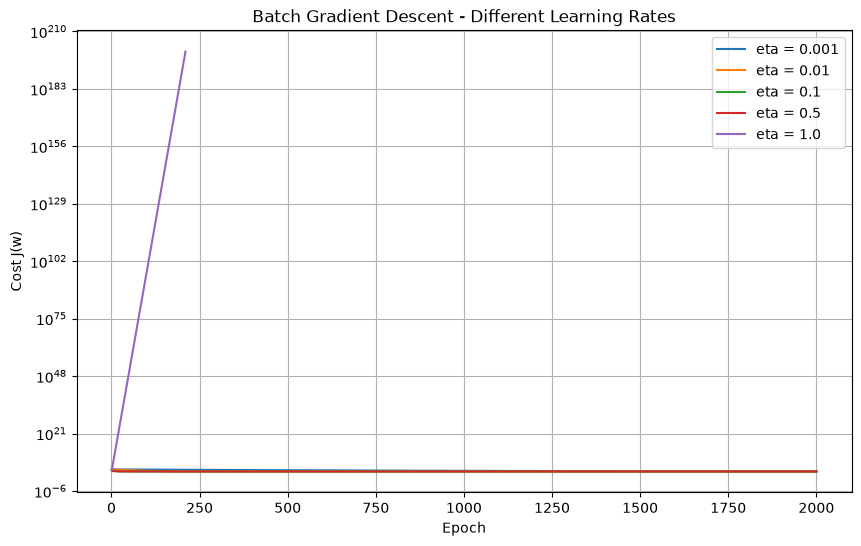

In [233]:
plt.figure(figsize=(10, 6))

for eta in learning_rates:
    plt.plot(
        range(1, epochs + 1),
        gd_results[eta]["costs"],
        label=f"eta = {eta}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w)")
plt.title("Batch Gradient Descent - Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

In [234]:
results_table = pd.DataFrame([
    {
        "Learning Rate": eta,
        "Final Cost": gd_results[eta]["final_cost"],
        "Final Relative Distance": gd_results[eta]["final_distance"],
        "First Epoch < 1e-3": gd_results[eta]["first_epoch"]
    }
    for eta in learning_rates
])

results_table

,Learning Rate,Final Cost,Final Relative Distance,First Epoch < 1e-3
0,0.001,1723.402889,0.405113,not reached
1,0.010,1503.686676,0.334521,not reached
2,0.100,1491.892636,0.081792,not reached
3,0.500,1491.145907,0.000155,1524
4,1.000,inf,inf,not reached


The learning rate affects how fast gradient descent converges. The learning rate 0.5 was the fastest and reached the required accuracy at epoch 1524. The learning rate 1.0 diverged.

### B

In [235]:
X_train_bias = add_bias(X_train)
N = X_train_bias.shape[0]

H = (X_train_bias.T @ X_train_bias) / N

lambda_max = np.max(np.linalg.eigvalsh(H))
eta_threshold = 2 / lambda_max

print("Lambda max:", lambda_max)
print("Learning rate threshold:", eta_threshold)

Lambda max: 3.954755032050376
Learning rate threshold: 0.5057203249737274


In [236]:
eta_converge = 0.95 * eta_threshold
eta_diverge = 1.05 * eta_threshold

threshold_results = {}

for eta in [eta_converge, eta_diverge]:
    w, costs, distances = batch_gradient_descent(
        X_train, y_train, eta, epochs, w_star
    )

    threshold_results[eta] = {
        "costs": costs,
        "distances": distances,
        "final_cost": costs[-1],
        "final_distance": distances[-1]
    }

print("Converging eta:", eta_converge)
print("Final cost:", threshold_results[eta_converge]["final_cost"])

print("\nDiverging eta:", eta_diverge)
print("Final cost:", threshold_results[eta_diverge]["final_cost"])

Converging eta: 0.48043430872504106
Final cost: 1491.145909733976

Diverging eta: 0.5310063412224139
Final cost: 3.2448118178607836e+168


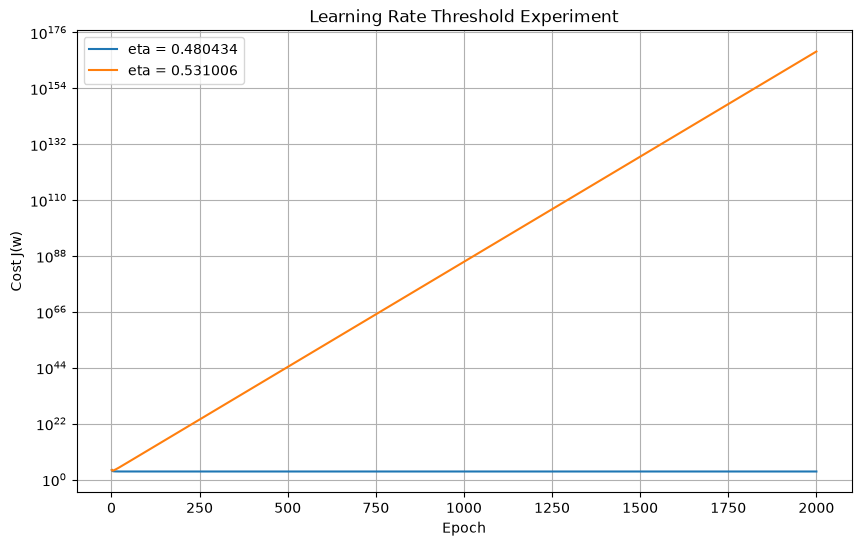

In [237]:
plt.figure(figsize=(10, 6))

for eta, result in threshold_results.items():
    plt.plot(
        range(1, epochs + 1),
        result["costs"],
        label=f"eta = {eta:.6f}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w)")
plt.title("Learning Rate Threshold Experiment")
plt.legend()
plt.grid(True)
plt.show()

The learning rate (0.95(2/\lambda_{\max})) converges, while (1.05(2/\lambda_{\max})) diverges.

From the error equation:

[
e^{(t+1)}=(I-\eta H)e^{(t)}
]

For gradient descent to converge, the learning rate must satisfy:

[
\boxed{0<\eta<\frac{2}{\lambda_{\max}}}
]

Therefore, (2/\lambda_{\max}) is the maximum learning-rate threshold for convergence.

## 7

In [238]:
X_raw = splits["Diabetes"]["X_train"]
y_train = splits["Diabetes"]["y_train"]

X_raw_bias = add_bias(X_raw)

H_raw = (X_raw_bias.T @ X_raw_bias) / len(y_train)

lambda_max_raw = np.max(np.linalg.eigvalsh(H_raw))
threshold_raw = 2 / lambda_max_raw

condition_raw = np.linalg.cond(X_raw_bias.T @ X_raw_bias)

print("Raw condition number:", condition_raw)
print("Raw learning rate threshold:", threshold_raw)

Raw condition number: 55778473.21753785
Raw learning rate threshold: 2.7427928748390996e-05


In [239]:
w_star_raw = normal_equation(X_raw, y_train)
raw_learning_rates = [1e-8, 1e-6, 1e-5, 1e-4]

raw_results = {}

for eta in raw_learning_rates:
    w, costs, distances = batch_gradient_descent(
        X_raw, y_train, eta, 2000, w_star_raw
    )

    raw_results[eta] = {
        "weights": w,
        "costs": costs,
        "distances": distances,
        "final_cost": costs[-1],
        "final_distance": distances[-1]
    }

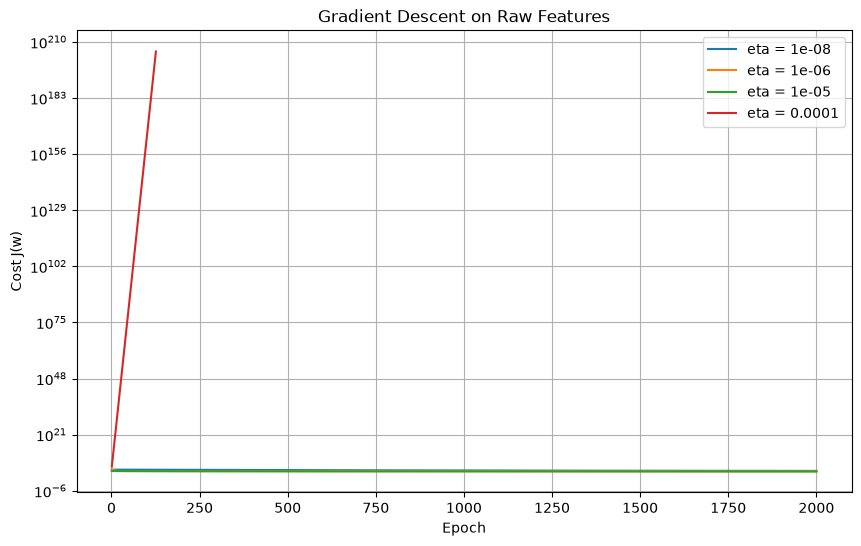

In [240]:
plt.figure(figsize=(10, 6))

for eta in raw_learning_rates:
    plt.plot(
        range(1, 2001),
        raw_results[eta]["costs"],
        label=f"eta = {eta}"
    )

plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Cost J(w)")
plt.title("Gradient Descent on Raw Features")
plt.legend()
plt.grid(True)
plt.show()

In [262]:
raw_results_table = pd.DataFrame([
    {
        "Learning Rate": eta,
        "Final Cost": result["final_cost"],
        "Final Relative Distance": result["final_distance"],
        "First Epoch < 1e-3": next(
            (i + 1 for i, d in enumerate(result["distances"]) if d < 1e-3),
            "not reached"
        )
    }
    for eta, result in raw_results.items()
])

raw_results_table

,Learning Rate,Final Cost,Final Relative Distance,First Epoch < 1e-3
0,1.000000e-08,3583.532102,0.999999,not reached
1,1.000000e-06,2388.752582,0.999968,not reached
2,1.000000e-05,1827.534910,0.999846,not reached
3,1.000000e-04,inf,inf,not reached


In [241]:
X_std_bias = add_bias(X_train)
H_std = (X_std_bias.T @ X_std_bias) / len(y_train)

lambda_max_std = np.max(np.linalg.eigvalsh(H_std))

comparison = pd.DataFrame({
    "": ["Standardized", "Raw"],
    "Condition Number": [
        np.linalg.cond(X_std_bias.T @ X_std_bias),
        condition_raw
    ],
    "Learning Rate Threshold": [
        2 / lambda_max_std,
        threshold_raw
    ]
})

comparison

,,Condition Number,Learning Rate Threshold
0,Standardized,5.057061e+02,0.505720
1,Raw,5.577847e+07,0.000027


Standardized features have a much smaller condition number than raw features. This allows gradient descent to use larger learning rates. Raw features require much smaller learning rates, so convergence is slower. The learning rate \(10^{-4}\) diverges, while the other raw runs do not reach the optimal cost within 2000 epochs.

## 8

In [242]:
def mini_batch_gd(X, y, eta, epochs, batch_size):
    X_bias = add_bias(X)
    N = len(y)

    w = np.zeros(X_bias.shape[1])
    rng = np.random.default_rng(42)

    epoch_costs = []
    update_costs = []

    for epoch in range(epochs):
        indices = rng.permutation(N)

        for start in range(0, N, batch_size):
            batch = indices[start:start + batch_size]

            X_batch = X_bias[batch]
            y_batch = y[batch]

            gradient = X_batch.T @ (X_batch @ w - y_batch) / len(batch)
            w -= eta * gradient

            error = X_bias @ w - y
            update_costs.append((error @ error) / (2 * N))

        epoch_costs.append(update_costs[-1])

    return w, epoch_costs, update_costs

In [243]:
X_train = scaled_splits["Diabetes"]["X_train"]
y_train = scaled_splits["Diabetes"]["y_train"]

N = len(y_train)
batch_sizes = [1, 16, 64, N]

mini_results = {}

for B in batch_sizes:
    w, epoch_costs, update_costs = mini_batch_gd(
        X_train, y_train,
        eta=0.01,
        epochs=100,
        batch_size=B
    )

    mini_results[B] = {
        "weights": w,
        "epoch_costs": epoch_costs,
        "update_costs": update_costs
    }

print(mini_results[1].keys())

dict_keys(['weights', 'epoch_costs', 'update_costs'])


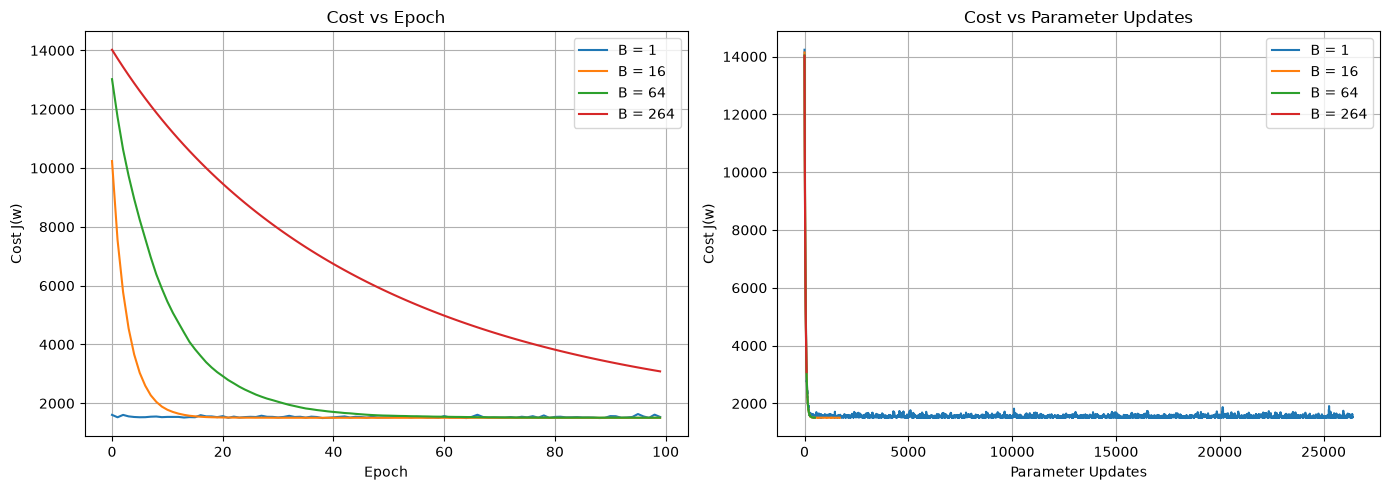

In [244]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for B in batch_sizes:
    axes[0].plot(
        mini_results[B]["epoch_costs"],
        label=f"B = {B}"
    )

    axes[1].plot(
        mini_results[B]["update_costs"],
        label=f"B = {B}"
    )

axes[0].set_title("Cost vs Epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cost J(w)")
axes[0].legend()
axes[0].grid(True)

axes[1].set_title("Cost vs Parameter Updates")
axes[1].set_xlabel("Parameter Updates")
axes[1].set_ylabel("Cost J(w)")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [245]:
sgd_rates = [0.001, 0.01, 0.1]

sgd_results = {}

for eta in sgd_rates:
    w, costs, update_costs = mini_batch_gd(
        X_train, y_train,
        eta=eta,
        epochs=100,
        batch_size=1
    )

    sgd_results[eta] = update_costs

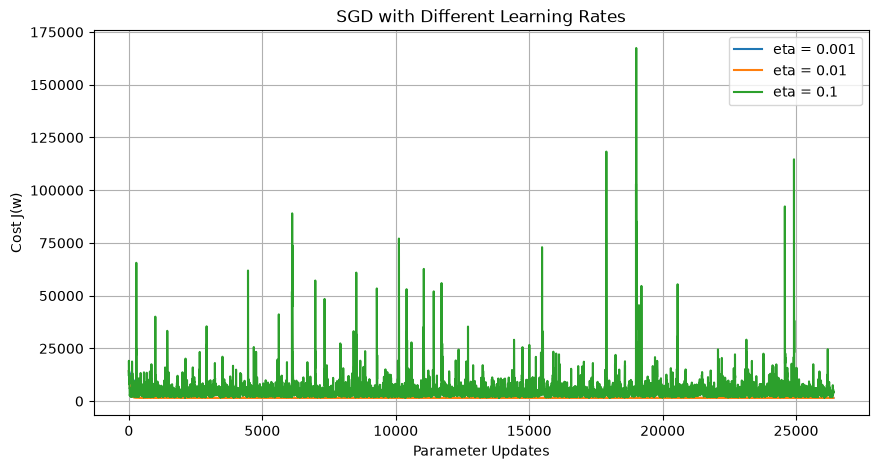

In [246]:
plt.figure(figsize=(10, 5))

for eta in sgd_rates:
    plt.plot(
        sgd_results[eta],
        label=f"eta = {eta}"
    )

plt.xlabel("Parameter Updates")
plt.ylabel("Cost J(w)")
plt.title("SGD with Different Learning Rates")
plt.legend()
plt.grid(True)
plt.show()

As the learning rate increases, the noise in SGD also increases. With a learning rate of 0.001, the updates are smaller and the cost curve is smoother. At 0.01, the fluctuations become more noticeable. At 0.1, the updates are much larger, causing greater fluctuations in the cost. Therefore, higher learning rates make SGD noisier.

## 9

In [247]:
def ridge_regression(X, y, lam):
    X_bias = add_bias(X)
    N = len(y)

    I0 = np.eye(X_bias.shape[1])
    I0[0, 0] = 0

    A = (X_bias.T @ X_bias) / N + lam * I0
    b = (X_bias.T @ y) / N

    w = np.linalg.solve(A, b)

    return w

In [248]:
X_example = np.array([[1], [2], [3]])
y_example = np.array([2, 3, 5])

w_ridge = ridge_regression(X_example, y_example, lam=1)

print(w_ridge)

[2.13333333 0.6       ]


In [249]:
def degree2_features(X):
    features = [X]
    names = list(diabetes.feature_names)

    for i in range(X.shape[1]):
        for j in range(i, X.shape[1]):
            # Drop sex squared (sex is feature index 1)
            if i == 1 and j == 1:
                continue

            features.append((X[:, i] * X[:, j]).reshape(-1, 1))
            names.append(f"{diabetes.feature_names[i]}*{diabetes.feature_names[j]}")

    return np.column_stack(features), names


# Use the original, unstandardized splits
data = splits["Diabetes"]

X_train_exp, feature_names_exp = degree2_features(data["X_train"])
X_val_exp, _ = degree2_features(data["X_val"])
X_test_exp, _ = degree2_features(data["X_test"])

# Standardize using training statistics only
exp_scaler = Standardizer()

X_train_exp = exp_scaler.fit(X_train_exp).transform(X_train_exp)
X_val_exp = exp_scaler.transform(X_val_exp)
X_test_exp = exp_scaler.transform(X_test_exp)

y_train = data["y_train"]
y_val = data["y_val"]
y_test = data["y_test"]

print("Number of expanded features:", X_train_exp.shape[1])

Number of expanded features: 64


In [263]:
X_exp_bias = add_bias(X_train_exp)

condition_expanded = np.linalg.cond(
    X_exp_bias.T @ X_exp_bias
)

print("Expanded condition number:", condition_expanded)

Expanded condition number: 1289356235.088888


In [250]:
lambdas = np.concatenate(([0], np.logspace(-3, 1, 9)))

X_original = scaled_splits["Diabetes"]["X_train"]
X_val_original = scaled_splits["Diabetes"]["X_val"]
X_test_original = scaled_splits["Diabetes"]["X_test"]

datasets_ridge = {
    "Original": (
        X_original, X_val_original, X_test_original
    ),
    "Expanded": (
        X_train_exp, X_val_exp, X_test_exp
    )
}

ridge_results = {}

for name, (Xtr, Xva, Xte) in datasets_ridge.items():

    results = []

    for lam in lambdas:
        w = ridge_regression(Xtr, y_train, lam)

        val_pred = add_bias(Xva) @ w
        test_pred = add_bias(Xte) @ w

        results.append({
            "lambda": lam,
            "weights": w,
            "val_rmse": rmse(y_val, val_pred),
            "test_rmse": rmse(y_test, test_pred)
        })

    ridge_results[name] = results

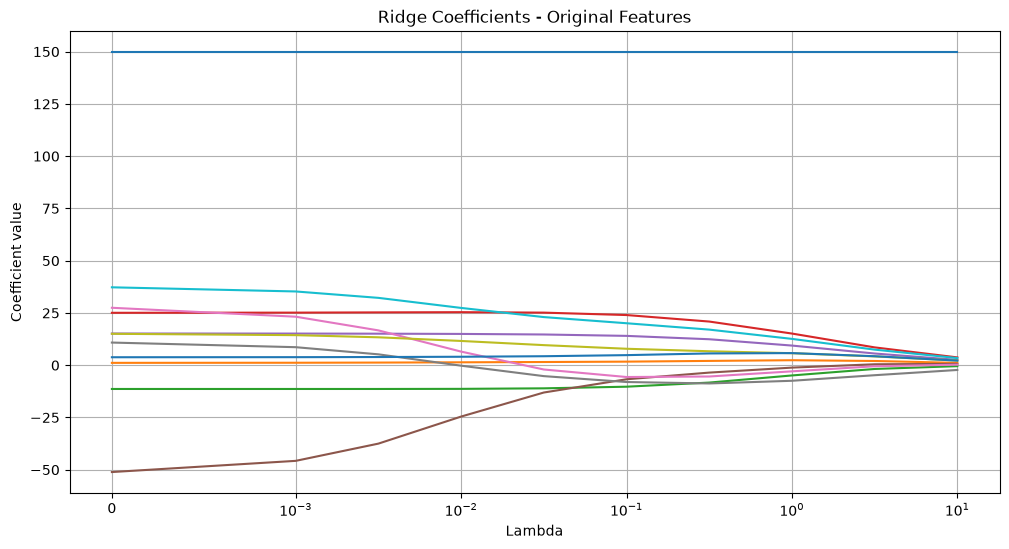

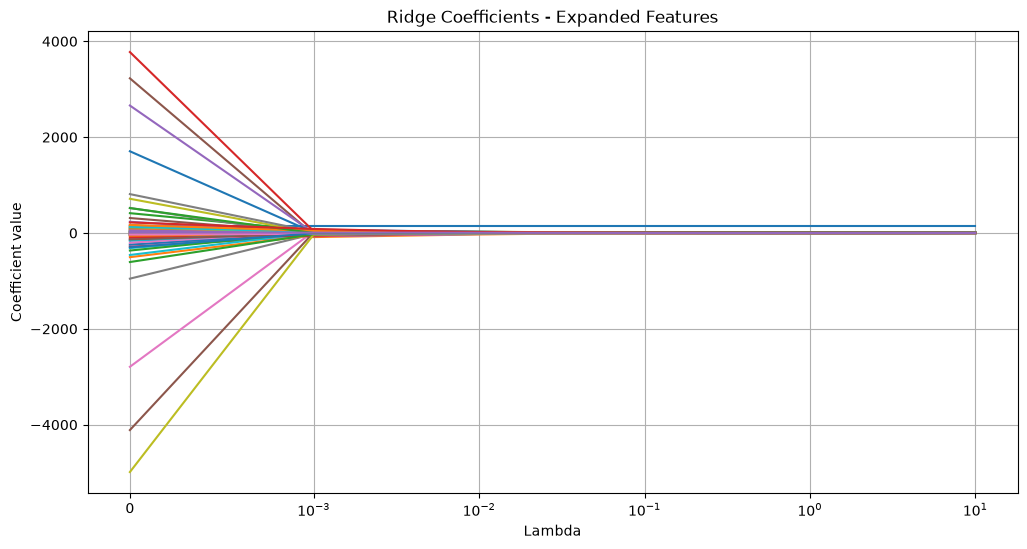

In [251]:
for name in ["Original", "Expanded"]:

    plt.figure(figsize=(12, 6))

    for i in range(len(ridge_results[name][0]["weights"])):
        coefficients = [
            result["weights"][i]
            for result in ridge_results[name]
        ]

        plt.plot(lambdas, coefficients, label=f"w{i}")

    plt.xscale("symlog", linthresh=0.001)
    plt.xlabel("Lambda")
    plt.ylabel("Coefficient value")
    plt.title(f"Ridge Coefficients - {name} Features")
    plt.grid(True)
    plt.show()

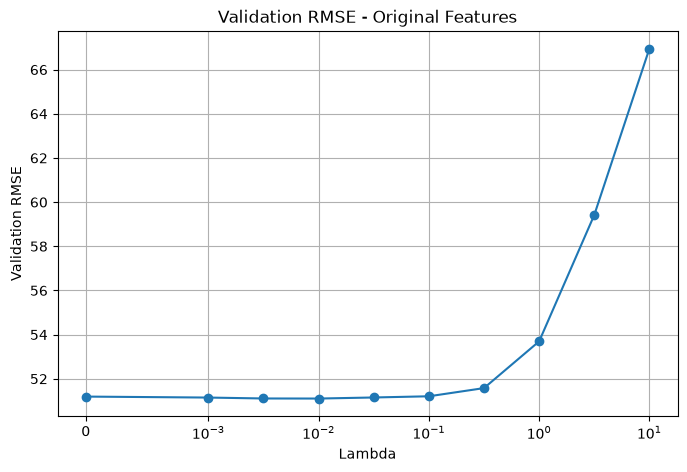

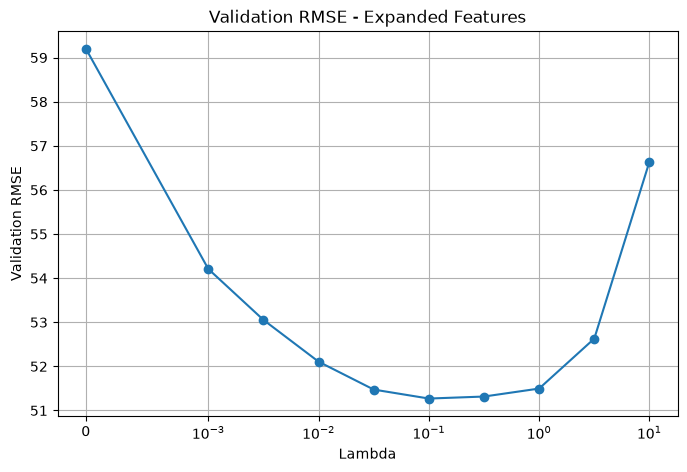

In [252]:
for name in ["Original", "Expanded"]:

    val_errors = [
        result["val_rmse"]
        for result in ridge_results[name]
    ]

    plt.figure(figsize=(8, 5))
    plt.plot(lambdas, val_errors, marker="o")

    plt.xscale("symlog", linthresh=0.001)
    plt.xlabel("Lambda")
    plt.ylabel("Validation RMSE")
    plt.title(f"Validation RMSE - {name} Features")
    plt.grid(True)
    plt.show()

In [253]:
for name in ["Original", "Expanded"]:

    best_result = min(
        ridge_results[name],
        key=lambda result: result["val_rmse"]
    )

    zero_result = ridge_results[name][0]

    print(f"\n{name} Features")
    print("Best lambda:", best_result["lambda"])
    print("Best validation RMSE:", best_result["val_rmse"])
    print("Test RMSE at best lambda:", best_result["test_rmse"])
    print("Test RMSE at lambda = 0:", zero_result["test_rmse"])


Original Features
Best lambda: 0.01
Best validation RMSE: 51.10474905057183
Test RMSE at best lambda: 53.9584521494208
Test RMSE at lambda = 0: 54.15641293326043

Expanded Features
Best lambda: 0.1
Best validation RMSE: 51.27063977293423
Test RMSE at best lambda: 53.615580116744916
Test RMSE at lambda = 0: 62.133373392121314


In [264]:
lam = 0.1
eta = 0.4
epochs = 3000

X_bias = add_bias(X_original)
N = len(y_train)

H = (X_bias.T @ X_bias) / N
b = (X_bias.T @ y_train) / N

w = np.zeros(X_bias.shape[1])

for epoch in range(epochs):
    gradient = H @ w - b

    # Do not regularize the bias
    gradient[1:] += lam * w[1:]

    w -= eta * gradient

w_ridge_closed = ridge_regression(
    X_original, y_train, lam
)

distance = (
    np.linalg.norm(w - w_ridge_closed)
    / np.linalg.norm(w_ridge_closed)
)

print("Relative distance:", distance)

Relative distance: 2.493508106868424e-16


In [265]:
ridge_model = Ridge(alpha=lam * N)

ridge_model.fit(X_original, y_train)

w_sklearn_ridge = np.concatenate(
    ([ridge_model.intercept_],
     ridge_model.coef_)
)

print(
    "Scratch vs sklearn Ridge difference:",
    np.linalg.norm(w_ridge_closed - w_sklearn_ridge)
)

Scratch vs sklearn Ridge difference: 2.421562104571301e-13


Ridge provides a small improvement with the 10 original features because the number of features (d = 10) is much smaller than the number of training samples (N = 264), so overfitting is already limited. However, with the degree-2 expansion, we have 64 features compared to only 264 training samples, which increases the risk of overfitting. Ridge regularization reduces large coefficients and improves generalization, leading to a larger improvement in validation RMSE. The bias must not be penalized because it controls the model's baseline prediction, and penalizing it would unnecessarily force the intercept toward zero.

## 10

In [254]:

X_train = scaled_splits["Diabetes"]["X_train"]
X_test = scaled_splits["Diabetes"]["X_test"]

y_train = splits["Diabetes"]["y_train"]
y_test = splits["Diabetes"]["y_test"]

N_train = len(y_train)

def relative_distance(w, w_star):
    return np.linalg.norm(w - w_star) / np.linalg.norm(w_star)

In [255]:
start = time.perf_counter()
w_star = normal_equation(X_train, y_train)
normal_time = time.perf_counter() - start

print("Normal equation time:", normal_time)

Normal equation time: 0.00026151099882554263


In [256]:
def evaluate_model(name, w, fit_time):
    predictions = add_bias(X_test) @ w

    return {
        "Model": name,
        "Test RMSE": rmse(y_test, predictions),
        "Relative Distance": relative_distance(w, w_star),
        "Fit Time (seconds)": fit_time
    }

In [257]:
results = []

# 1. Normal Equation
results.append(
    evaluate_model("Normal Equation", w_star, normal_time)
)


# 2. Batch Gradient Descent
start = time.perf_counter()

w_batch, costs, distances = batch_gradient_descent(
    X_train, y_train,
    eta=0.5,
    epochs=2000,
    w_star=w_star
)

batch_time = time.perf_counter() - start

results.append(
    evaluate_model("Batch GD", w_batch, batch_time)
)


# 3. Mini-batch Gradient Descent
start = time.perf_counter()

w_mini, costs, update_costs = mini_batch_gd(
    X_train, y_train,
    eta=0.01,
    epochs=100,
    batch_size=16
)

mini_time = time.perf_counter() - start

results.append(
    evaluate_model("Mini-batch GD (B=16)", w_mini, mini_time)
)


# 4. Ridge Regression (from scratch)
start = time.perf_counter()

w_ridge = ridge_regression(X_train, y_train, lam=0.1)

ridge_time = time.perf_counter() - start

results.append(
    evaluate_model("Ridge (scratch)", w_ridge, ridge_time)
)

In [258]:
# 5. LinearRegression
start = time.perf_counter()

linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

linear_time = time.perf_counter() - start

w_linear = np.concatenate(([linear_model.intercept_], linear_model.coef_))

results.append(
    evaluate_model("LinearRegression", w_linear, linear_time)
)


# 6. Ridge from sklearn
start = time.perf_counter()

ridge_model = Ridge(alpha=0.1 * N_train)
ridge_model.fit(X_train, y_train)

sk_ridge_time = time.perf_counter() - start

w_sk_ridge = np.concatenate(([ridge_model.intercept_], ridge_model.coef_))

results.append(
    evaluate_model("Ridge (sklearn)", w_sk_ridge, sk_ridge_time)
)

In [259]:
sgd_rates = [0.001, 0.01, 0.1]

for eta in sgd_rates:
    start = time.perf_counter()

    sgd_model = SGDRegressor(
        penalty=None,
        learning_rate="constant",
        eta0=eta,
        max_iter=1000,
        tol=None,
        random_state=42
    )

    sgd_model.fit(X_train, y_train)

    sgd_time = time.perf_counter() - start

    w_sgd = np.concatenate(([sgd_model.intercept_[0]], sgd_model.coef_))

    results.append(
        evaluate_model(f"SGDRegressor (eta={eta})", w_sgd, sgd_time)
    )

In [260]:
results_df = pd.DataFrame(results)
results_df

,Model,Test RMSE,Relative Distance,Fit Time (seconds)
0,Normal Equation,54.156413,0.000000e+00,0.000262
1,Batch GD,54.156254,1.546262e-04,0.051035
2,Mini-batch GD (B=16),53.895449,3.421471e-01,0.028174
3,Ridge (scratch),53.708925,3.636136e-01,0.000187
4,LinearRegression,54.156413,8.801221e-15,0.001530
5,Ridge (sklearn),53.708925,3.636136e-01,0.009998
6,SGDRegressor (eta=0.001),54.088486,4.976050e-02,0.065534
7,SGDRegressor (eta=0.01),54.898061,5.031993e-02,0.027321
8,SGDRegressor (eta=0.1),71.449348,3.949685e-01,0.022929


In [261]:
print("Normal Equation vs LinearRegression:")
print(np.linalg.norm(w_star - w_linear))

print("\nRidge scratch vs Ridge sklearn:")
print(np.linalg.norm(w_ridge - w_sk_ridge))

Normal Equation vs LinearRegression:
1.4870203685843355e-12

Ridge scratch vs Ridge sklearn:
2.421562104571301e-13


The Normal Equation and LinearRegression agree almost exactly, and the scratch Ridge and sklearn Ridge also agree because they use equivalent mathematical formulas and regularization parameters. However, Batch GD, Mini-batch GD, and SGDRegressor may differ from the exact solutions because they use iterative optimization rather than solving directly. Their results depend on the learning rate, number of updates, batch size, and convergence behavior.